In [17]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Oscillator Tracking with Kalman Filters

This notebook covers three models for tracking oscillatory signals:

| Section | Model | Representation | Typical use |
|---|---|---|---|
| 1 | `OscillatorModel` | Real-valued `[pos, vel]` | Mechanical resonator, seismometer, LC circuit |
| 2 | `AnalyticOscillatorModel` | Complex `[Re(ψ), Im(ψ)]` rotating frame | Narrowband signal tracking, lock-in amplifier |
| 3 | `HarmonicOscillatorModel` | Multi-partial composite | Inharmonic strings, suspension violin modes |

---

**Physical motivation:**  
Many physical systems behave as damped harmonic oscillators:
- A pendulum: $\ddot{\theta} + (\omega_0^2/Q)\dot{\theta} + \omega_0^2 \theta = 0$
- A spring-mass system: $m\ddot{x} + b\dot{x} + kx = 0$ with $\omega_0 = \sqrt{k/m}$, $Q = m\omega_0/b$
- An LC resonator with resistance: $\omega_0 = 1/\sqrt{LC}$, $Q = \omega_0 L / R$

The Kalman filter provides optimal state estimation when only **position** (or voltage, angle) is measurable — not velocity.


## Section 1 — Damped Harmonic Oscillator

### Model

State vector: $\mathbf{x} = [x,\; \dot{x}]^\top$

Continuous-time dynamics:
$$
\ddot{x} = -\omega_0^2 x - \frac{\omega_0}{Q}\dot{x}
$$

Discretized via first-order (Euler) approximation:
$$
F = \begin{pmatrix} 1 & \Delta t \\ -\omega_0^2 \Delta t & 1 - \frac{\omega_0}{Q}\Delta t \end{pmatrix}
$$
This is accurate when $\omega_0 \Delta t \ll 1$ (high sample rate relative to the resonance frequency).  
Measurement: $z_k = x_k + v_k$ (position only, $H = [1, 0]$).

Parameters:
- `w0` — natural angular frequency [rad/s]
- `Q` — quality factor (higher Q = less damping, more oscillations before decay)
- `measurement_uncertainty` — sensor noise std $r$ [same units as $x$]
- `process_uncertainty` — model mismatch noise std $q$ (deviations from perfect harmonic motion)

### Observability
Only position is measured. Velocity must be inferred from two or more position measurements.  
The filter is observable because the **Kalman observability matrix**
$$
\mathcal{O} = \begin{pmatrix} H \\ H F \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 1 & \Delta t \end{pmatrix}
$$
has rank 2 — the position at two consecutive timesteps determines both $x$ and $\dot{x}$.  
In practice, the filter needs ~$1/Q$ oscillation periods to converge to the true velocity from a bad initial guess.

Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Sampling completed      18.2 ms     18.2 ms
    2.  Filtering completed    169.2 ms    151.0 ms
  ───   ───────────────────   ─────────   ─────────
        total                  227.7 ms


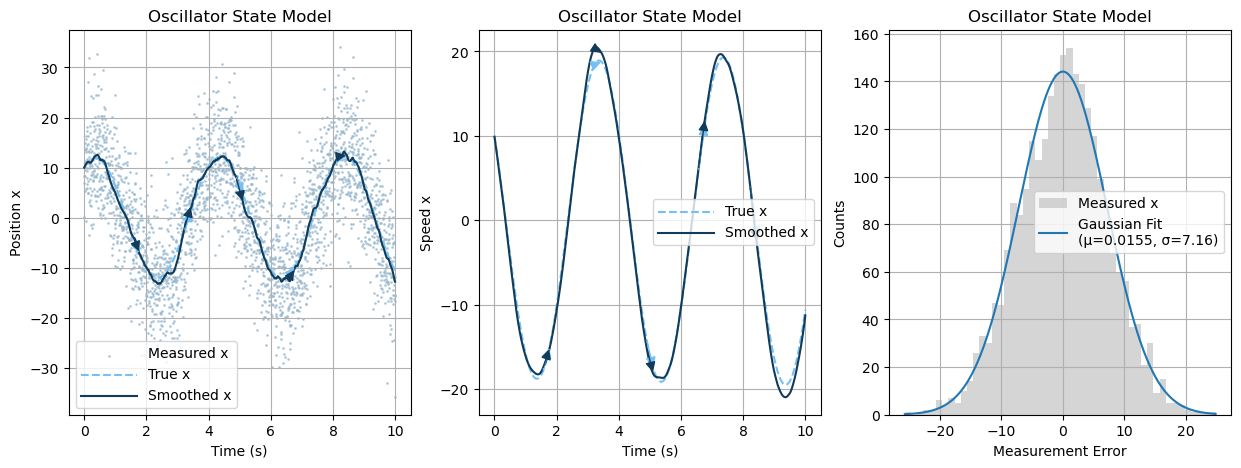

In [18]:
from kalman.apps.oscillators import OscillatorModel

oscillator = OscillatorModel("x", sample_rate=256,
                             w0=np.pi/2,
                             Q=10000,
                             measurement_uncertainty=50,
                             process_uncertainty=0.1,
                             random_seed=42)
oscillator.initial_state([10, 10])  # [x₀, ẋ₀]

chrono.restart()
sample = oscillator.sample(10)
chrono.lap("Sampling completed")
record = oscillator.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)

record.plot(sample=sample, fig=canvas[0], component="position", ideal=False)
record.plot(sample=sample, fig=canvas[1], component="speed", ideal=False)
record.plot_error(sample=sample, fig=canvas[2])

chrono.summary()

### Interpreting the results

- **Position**: smoother output (dashed) hugs the truth closely; measurement noise (gray dots) is significantly attenuated.
- **Speed**: entirely inferred from position; the transient at $t=0$ reflects initial covariance $P_0$ — it decays as the filter builds confidence in $\dot{x}$.
- **Error**: residuals should scatter around zero. Persistent bias → Q/R miscalibration or model mismatch.

**High-Q regimes ($Q \gg 100$)**: The oscillator barely damps, so position and velocity are tightly coupled.  The Kalman gain is small (filter trusts the model heavily); smoothing gives the biggest improvement here.

> **Try it:** set `Q=10` (heavily damped) and observe how the oscillator decays quickly and the velocity estimate is less smooth.

## Section 2 — Analytic Oscillator in a Rotating Reference Frame

### Motivation

For **narrowband** signals near a known carrier frequency $\omega_c$, it is far more efficient to work in a **rotating reference frame** that co-rotates with the carrier.  
In this frame the signal appears nearly DC — a slowly varying complex amplitude $\psi(t)$ — instead of a rapidly oscillating waveform.

This is the principle behind:
- **Lock-in amplifiers** in laboratory instruments
- **Coherent demodulation** in radio receivers
- **Slowly-varying envelope (SVE) methods** in GW detector physics

### Signal decomposition

The physical signal is real:
$$
x(t) = \operatorname{Re}\!\left[\psi(t)\,e^{i\omega_c t}\right]
\quad\Rightarrow\quad
\psi(t) = \underbrace{\operatorname{Re}(\psi)}_{\text{in-phase}} + i\underbrace{\operatorname{Im}(\psi)}_{\text{quadrature}}
$$

### State-space model in the rotating frame

State: $\mathbf{x} = [\operatorname{Re}(\psi),\; \operatorname{Im}(\psi)]^\top$ — slowly-varying complex amplitude.

$$
\dot{\psi} = \underbrace{\begin{pmatrix} -\gamma & -\Delta\omega \\ \Delta\omega & -\gamma \end{pmatrix}}_{A_c} \psi
\qquad
\gamma = \frac{\omega_0}{2Q}, \quad \Delta\omega = \omega_0 - \omega_c
$$

Discretized: $F = e^{A_c \Delta t}$, $H = I_2$ (identity — the state IS the observable in the rotating frame).

### Measurement pipeline

Measurements $z_k$ are **real scalars** — raw sensor readings, exactly as in Soma (2000):

$$
z_k = x(t_k) + v_k = \operatorname{Re}\!\left[\psi(t_k)\,e^{i\omega_c t_k}\right] + v_k
$$

`model.preprocess` converts them into the rotating frame automatically:
1. **Hilbert transform** — forms the analytic signal $z_k + i\,\mathcal{H}[z_k]$
2. **Demodulation** — multiplies by $e^{-i\omega_c t}$ to extract $\psi_k$

`model.postprocess` inverts this: $[\operatorname{Re}(\psi), \operatorname{Im}(\psi)] \;\to\; x(t) = \operatorname{Re}[\psi\,e^{i\omega_c t}]$.

The Kalman filter itself always operates on the (complex-valued, slow) $\psi$ — the pre/postprocess steps are transparent to it.

### Key parameter: $\Delta\omega = \omega_0 - \omega_c$

| Condition | Effect on state | Phase plot |
|---|---|---|
| $\omega_c = \omega_0$ → $\Delta\omega = 0$ | $\psi$ decays radially, no rotation — **lock-in mode** | Spiral inward (or fixed point for high Q) |
| $\omega_c \neq \omega_0$ → $\Delta\omega \neq 0$ | $\psi$ precesses at rate $\Delta\omega$ | Circle at radius $\|\psi\|$ |

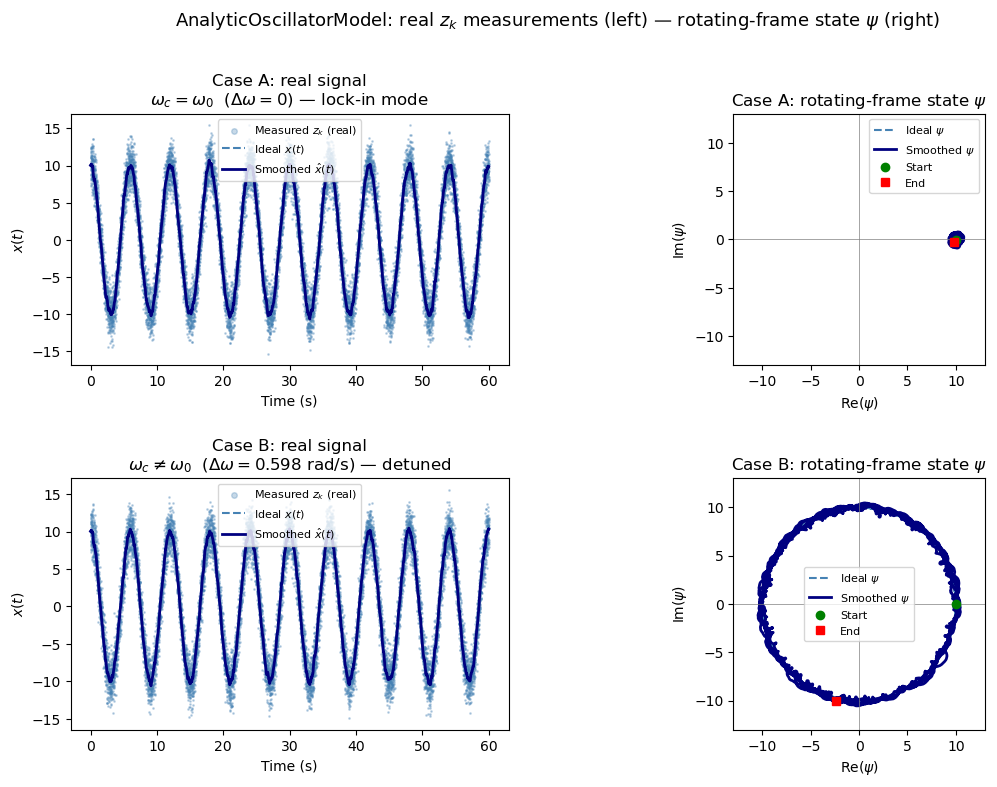

In [19]:
from kalman.apps.oscillators import AnalyticOscillatorModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

w0 = np.pi / 3    # natural frequency
fs = 256
T  = 60

# ---------------------------------------------------------------
# Case A: wc = w0  →  Δω = 0  →  locked carrier  (lock-in mode)
# ---------------------------------------------------------------
model_A = AnalyticOscillatorModel("f0", sample_rate=fs, w0=w0, wc=w0,
                                  Q=10000, measurement_uncertainty=2,
                                  process_uncertainty=0.01, random_seed=42)
model_A.initial_state([10, 0])

# sample.zk is a real scalar signal  x(t) + noise  — exactly Soma's z_k
sample_A = model_A.sample(T)
# preprocess=True (default): Hilbert transform + demodulate → rotating frame internally
record_A = model_A.filter(sample_A, smooth=True, reset=True)

# ---------------------------------------------------------------
# Case B: wc ≠ w0  →  Δω ≠ 0  →  detuned carrier (precessing)
# ---------------------------------------------------------------
wc_B = np.pi / 7
model_B = AnalyticOscillatorModel("f0", sample_rate=fs, w0=w0, wc=wc_B,
                                  Q=10000, measurement_uncertainty=2,
                                  process_uncertainty=0.01, random_seed=42)
model_B.initial_state([10, 0])

sample_B = model_B.sample(T)
record_B = model_B.filter(sample_B, smooth=True, reset=True)

# ---------------------------------------------------------------
# Plot: 2 rows (A, B) × 2 cols (real signal, rotating-frame phase)
# ---------------------------------------------------------------
t = record_A.time

ideal_A = model_A.ideal(T)   # (N, 2): [Re(ψ), Im(ψ)] — no noise
ideal_B = model_B.ideal(T)

fig = plt.figure(figsize=(13, 8))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.3)

dw_B = w0 - wc_B

cases = [
    (record_A, sample_A, ideal_A, model_A, 0.0,  "A", r"$\omega_c = \omega_0$  ($\Delta\omega = 0$) — lock-in mode"),
    (record_B, sample_B, ideal_B, model_B, dw_B, "B", rf"$\omega_c \neq \omega_0$  ($\Delta\omega = {dw_B:.3f}$ rad/s) — detuned"),
]

for row, (rec, smp, ideal, model, dw, label, title) in enumerate(cases):
    arg = model["wc"] * t   # carrier phase at each sample

    # Ideal real signal reconstructed from noiseless state trajectory
    x_ideal = ideal[:, 0] * np.cos(arg) - ideal[:, 1] * np.sin(arg)

    ax_sig = fig.add_subplot(gs[row, 0])
    ax_ph  = fig.add_subplot(gs[row, 1])

    # --- Real signal time series ---
    ax_sig.scatter(t, smp.zk[:, 0], s=1, alpha=0.3, color="steelblue", label=r"Measured $z_k$ (real)")
    ax_sig.plot(t, x_ideal,      "--", lw=1.5, color="steelblue", label=r"Ideal $x(t)$")
    ax_sig.plot(t, rec.zk[:, 0],       lw=2,   color="navy",      label=r"Smoothed $\hat{x}(t)$")
    ax_sig.set_xlabel("Time (s)")
    ax_sig.set_ylabel(r"$x(t)$")
    ax_sig.set_title(f"Case {label}: real signal\n{title}")
    ax_sig.legend(fontsize=8, markerscale=4)

    # --- Rotating-frame phase space: Re(ψ) vs Im(ψ) ---
    ax_ph.plot(ideal[:, 0],    ideal[:, 1],    "--", lw=1.5, color="steelblue", label=r"Ideal $\psi$")
    ax_ph.plot(rec.xk[:, 0],  rec.xk[:, 1],         lw=2,   color="navy",      label=r"Smoothed $\psi$")
    ax_ph.plot(rec.xk[0, 0],  rec.xk[0, 1],  "o", ms=6, color="green", label="Start", zorder=5)
    ax_ph.plot(rec.xk[-1, 0], rec.xk[-1, 1], "s", ms=6, color="red",   label="End",   zorder=5)
    ax_ph.set_xlabel(r"Re($\psi$)")
    ax_ph.set_ylabel(r"Im($\psi$)")
    ax_ph.set_title(f"Case {label}: rotating-frame state $\\psi$")
    ax_ph.set_aspect("equal")
    ax_ph.set_xlim(-13, 13); ax_ph.set_ylim(-13, 13)
    ax_ph.axhline(0, color="gray", lw=0.5); ax_ph.axvline(0, color="gray", lw=0.5)
    ax_ph.legend(fontsize=8)

fig.suptitle(r"AnalyticOscillatorModel: real $z_k$ measurements (left) — rotating-frame state $\psi$ (right)",
             fontsize=13, y=1.01)
plt.show()

### Reading the comparison plots

The left column shows **real measurements** $z_k$ (gray dots) — a raw oscillatory signal just like Soma's model.  
The right column shows the **rotating-frame state** $\psi$ — what the Kalman filter actually tracks.

**Case A — locked carrier ($\omega_c = \omega_0$, $\Delta\omega = 0$)**

- **Real signal**: a sustained oscillation at $\omega_0$; the smoother (solid) closely hugs the noiseless ideal (dashed)
- **Phase plot**: $\psi$ sits at a nearly fixed point $(10, 0)$ — stationary in the rotating frame (lock-in mode)
- The Kalman filter only needs to track a nearly-DC complex amplitude → minimal bandwidth required

**Case B — detuned carrier ($\omega_c \neq \omega_0$, $\Delta\omega \neq 0$)**

- **Real signal**: oscillates at $\omega_0$ but the smoother follows correctly despite the detuning
- **Phase plot**: $\psi$ traces a circle of radius $A = |\psi|$ at angular rate $\Delta\omega$ — the complex amplitude precesses continuously
- The green dot (start) is at $(10, 0)$; after $T = 10$ s the red square lands at the corresponding point on the circle

**Why the two views are complementary**  
The real signal plot shows $z_k$ — what a sensor delivers.  
The phase plot shows $\psi$ — the internal rotating-frame representation that makes the Kalman filter efficient.  
`model.preprocess` (Hilbert + demodulate) bridges the two; `model.postprocess` inverts back.

> **Try it:** swap `wc=w0` for `wc=w0*1.01` (1 % detuning) and observe how a slow precession appears in the phase plot while the real signal still looks like a clean sinusoid.

## Section 3 — Multi-Partial Oscillator with Inharmonicity

### Physical motivation

Real strings and suspension fibers have bending stiffness that shifts each partial away from exact integer multiples of the fundamental.  
The **Fletcher–Young inharmonicity formula** gives the $n$-th partial frequency:

$$f_n = n \cdot f_1 \cdot \sqrt{1 + B \cdot n^2}$$

where $B$ is the dimensionless **inharmonicity coefficient**.  For a cylindrical wire with Young's modulus $E$, diameter $d$, tension $T$, and length $L$:

$$B = \frac{\pi^3 E\, d^4}{64\, T L^2}$$

| System | $f_1$ | $B$ | Reference |
|---|---|---|---|
| Ideal string | — | $0$ | — |
| Piano steel string (A3, 1 mm) | 220 Hz | $\sim 3 \times 10^{-4}$ | Young 1952 |
| KAGRA sapphire suspension fiber | ~180 Hz | $\sim 0.10$ | Moisset et al. 2025 |

The large $B \approx 0.10$ of KAGRA sapphire fibers explains why the 2nd violin mode sits at ~420 Hz rather than $2 \times 180 = 360$ Hz — a 17 % shift driven entirely by fiber bending stiffness.

### Kalman tracking with `HarmonicOscillatorModel`

`HarmonicOscillatorModel` stacks one `OscillatorModel` per partial into a `KalmanCompositeModel` with **independent observations** — one narrowband measurement channel per partial.

Key helpers:

| Method | Description |
|---|---|
| `partial_frequencies(f1, B, n)` | Compute inharmonic $f_1,\ldots,f_n$ |
| `inharmonicity_from_material(E,d,T,L)` | Compute $B$ from wire physics |
| `fit_inharmonicity(peak_freqs)` | Least-squares fit $f_1$ and $B$ from measured peaks |

> **Note on frequency range:** `OscillatorModel` uses a first-order Euler scheme (accurate when $\omega_0 \Delta t \ll 1$). For audio-frequency partials (> 100 Hz), prefer `AnalyticOscillatorModel` sub-models in a rotating frame (see Extensions).


  n             B = 0         (ideal)     B = 3e-4  (piano, 1 mm steel)  B = 0.10  (KAGRA sapphire fiber)
---------------------------------------------------------------------------------------------------------
  1    220.00 Hz (+0.00)    220.03 Hz (+0.03)    230.74 Hz (+10.74)
  2    440.00 Hz (+0.00)    440.26 Hz (+0.26)    520.62 Hz (+80.62)
  3    660.00 Hz (+0.00)    660.89 Hz (+0.89)    909.75 Hz (+249.75)
  4    880.00 Hz (+0.00)    882.11 Hz (+2.11)   1418.96 Hz (+538.96)
  5   1100.00 Hz (+0.00)   1104.12 Hz (+4.12)   2057.91 Hz (+957.91)

Computed B values:
  Piano  (E=200 GPa, d=1 mm,   T=700 N,  L=0.65 m) : B = 3.28e-04
  KAGRA  (E=400 GPa, d=1.4 mm, T≈56 N,   L=0.35 m) : B = 1.08e-01


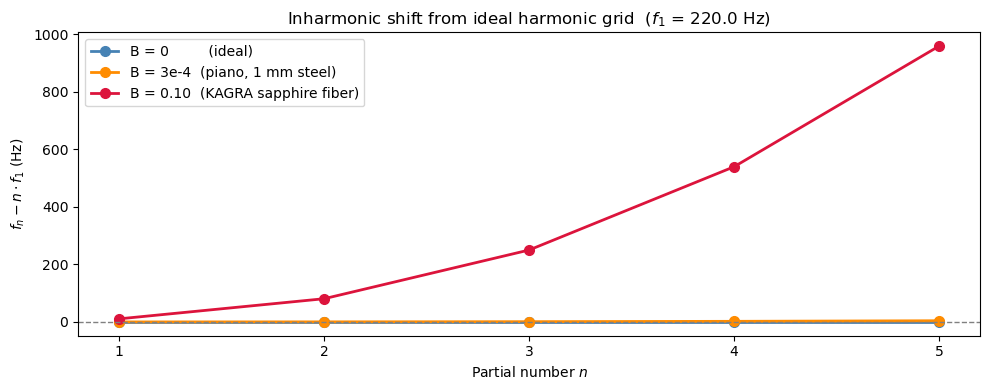

In [20]:
from kalman.apps.oscillators import HarmonicOscillatorModel
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Partial frequency comparison table ---
f1_ref = 220.0   # A3, Hz
n_harmonics = 5
ns = np.arange(1, n_harmonics + 1)

B_cases = {
    "B = 0         (ideal)":            0.0,
    "B = 3e-4  (piano, 1 mm steel)":   3e-4,
    "B = 0.10  (KAGRA sapphire fiber)": 0.10,
}

print(f"{'n':>3}", end="")
for label in B_cases:
    print(f"  {label:>32}", end="")
print()
print("-" * (3 + 34 * len(B_cases)))
for n in ns:
    print(f"  {n}", end="")
    for B in B_cases.values():
        fn = HarmonicOscillatorModel.partial_frequencies(f1_ref, B, n_harmonics)[n - 1]
        print(f"  {fn:8.2f} Hz ({fn - n * f1_ref:+.2f})", end="")
    print()

# --- 2. B from physical parameters ---
B_piano = HarmonicOscillatorModel.inharmonicity_from_material(
    E=200e9, d=1e-3,   T=700.0,     L=0.65)
B_kagra = HarmonicOscillatorModel.inharmonicity_from_material(
    E=400e9, d=1.4e-3, T=23*9.81/4, L=0.35)
print(f"\nComputed B values:")
print(f"  Piano  (E=200 GPa, d=1 mm,   T=700 N,  L=0.65 m) : B = {B_piano:.2e}")
print(f"  KAGRA  (E=400 GPa, d=1.4 mm, T≈56 N,   L=0.35 m) : B = {B_kagra:.2e}")

# --- 3. Frequency deviation plot ---
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["steelblue", "darkorange", "crimson"]
for (label, B), color in zip(B_cases.items(), colors):
    freqs = HarmonicOscillatorModel.partial_frequencies(f1_ref, B, n_harmonics)
    ax.plot(ns, freqs - ns * f1_ref, "o-", ms=7, lw=2, color=color, label=label)
ax.axhline(0, color="gray", lw=1, ls="--")
ax.set_xlabel("Partial number $n$")
ax.set_ylabel(r"$f_n - n \cdot f_1$ (Hz)")
ax.set_title(f"Inharmonic shift from ideal harmonic grid  ($f_1$ = {f1_ref} Hz)")
ax.legend()
ax.set_xticks(ns)
plt.tight_layout()
plt.show()


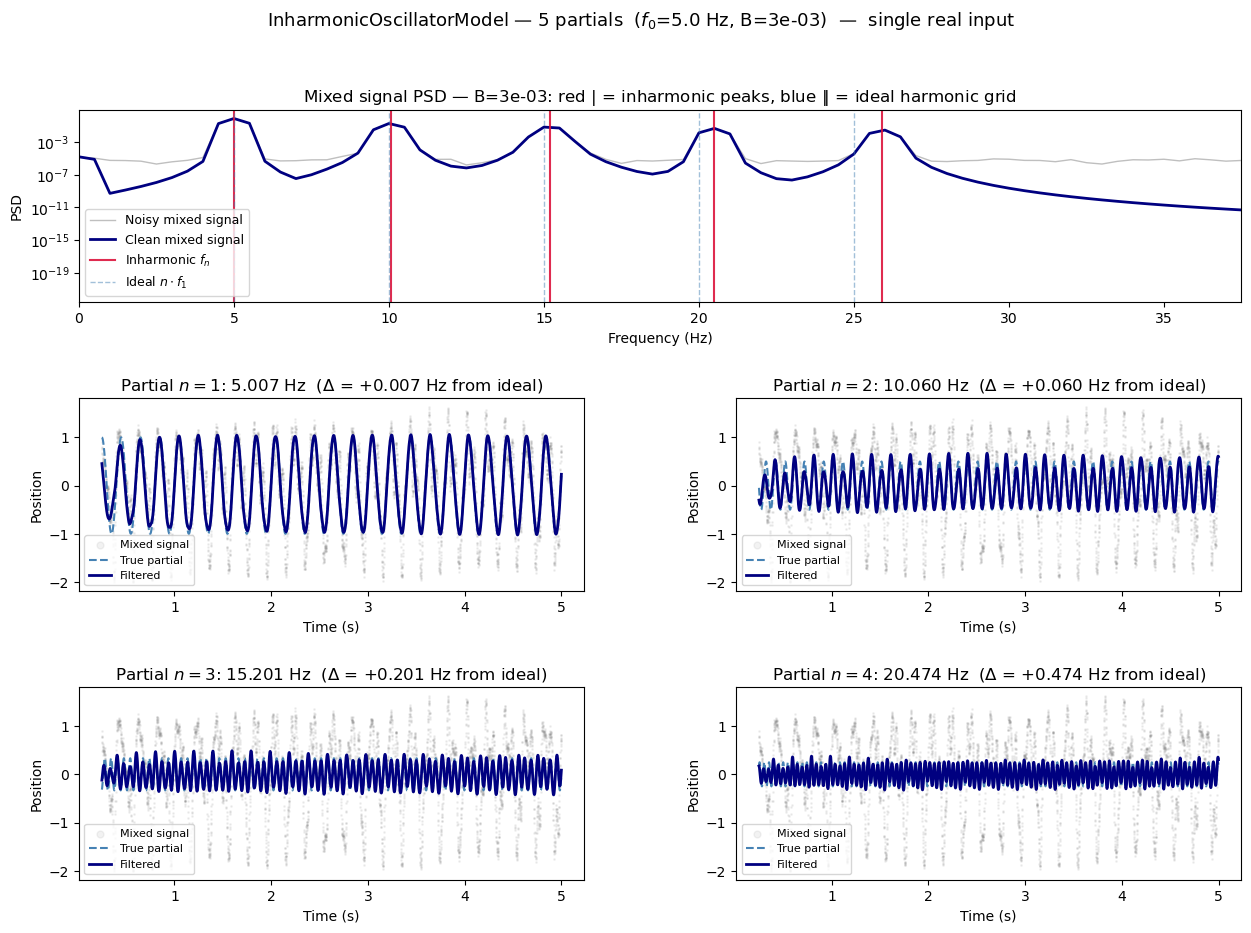


--- fit_inharmonicity: recover f0 and B from measured peak frequencies ---
  True:   f0 = 5.0000 Hz,  B = 3.00e-03
  Fitted: f0 = 5.0051 Hz,  B = 2.87e-03

--- KAGRA analogy (mean violin-mode frequencies) ---
  Fitted: f0 = 170.30 Hz,  B = 0.1301
  Residuals (fitted − measured): [ 0.94 -0.87  0.26] Hz


In [21]:

from kalman.apps.oscillators import InharmonicOscillatorModel
from scipy.signal import welch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# --- Simulation parameters ---
np.random.seed(42)
f1          = 5.0      # Hz  fundamental
B_true      = 3e-3     # inharmonicity
n_harmonics = 5
fs          = 1024     # Hz
T           = 5.0      # s
N           = int(T * fs)
t           = np.arange(N) / fs
sigma_n     = 0.05

model = InharmonicOscillatorModel(
    "demo", f0=f1, n_harmonics=n_harmonics, B=B_true,
    fs=fs, Q_factor=500,
    measurement_uncertainty=sigma_n,
    process_uncertainty=1e-6)

A_n = 1.0 / np.arange(1, n_harmonics + 1)   # 1/n amplitude falloff

for msub, A in zip(model.models, A_n):
    msub.initial_state([A, 0.0])
model.initial_state(np.vstack([msub.x0 for msub in model.models]))

# Single mixed signal — all partials summed into one real channel
signal_clean = sum(
    A * np.sin(2 * np.pi * fn * t)
    for A, fn in zip(A_n, model.partial_freqs)
)
zk = (signal_clean + sigma_n * np.random.randn(N)).reshape(-1, 1)   # (N, 1) real

record = model.filter(zk)
xk   = record.xk          # (N, 2×n_harmonics): rotating-frame states
skip = fs // 4            # skip first 0.25 s transient

# Reconstruct per-partial real estimates from rotating-frame state
def reconstruct_partial(xk, model, i):
    wc = model.models[i]["wc"]
    arg = wc * np.arange(len(xk)) / model.fs
    return xk[:, 2*i] * np.cos(arg) - xk[:, 2*i+1] * np.sin(arg)

# --- Figure: PSD + per-partial tracking ---
fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.3)

# Mixed-signal PSD
ax_psd = fig.add_subplot(gs[0, :])
f_psd, Snn = welch(zk[:, 0],      fs=fs, nperseg=2 * fs)
f_psd, Snc = welch(signal_clean,   fs=fs, nperseg=2 * fs)
ax_psd.semilogy(f_psd, Snn, lw=1, alpha=0.5, color="gray",  label="Noisy mixed signal")
ax_psd.semilogy(f_psd, Snc, lw=2,            color="navy",  label="Clean mixed signal")
for n, fn in enumerate(model.partial_freqs, 1):
    ax_psd.axvline(fn,     color="crimson",   lw=1.5, ls="-",  alpha=0.9,
                   label="Inharmonic $f_n$"    if n == 1 else None)
    ax_psd.axvline(n * f1, color="steelblue", lw=1.0, ls="--", alpha=0.5,
                   label="Ideal $n\\cdot f_1$" if n == 1 else None)
ax_psd.set_xlim(0, n_harmonics * f1 * 1.5)
ax_psd.set_xlabel("Frequency (Hz)")
ax_psd.set_ylabel("PSD")
ax_psd.set_title(
    f"Mixed signal PSD — B={B_true:.0e}: "
    r"red $\vert$ = inharmonic peaks, blue $\vert\!\vert$ = ideal harmonic grid")
ax_psd.legend(fontsize=9)

# Per-partial tracking panels (4 of 5)
for i in range(4):
    row, col = 1 + i // 2, i % 2
    ax = fig.add_subplot(gs[row, col])
    pos_true  = A_n[i] * np.sin(2 * np.pi * model.partial_freqs[i] * t)
    pos_filt  = reconstruct_partial(xk, model, i)
    dfreq     = model.partial_freqs[i] - (i + 1) * f1
    ax.scatter(t[skip:], zk[skip:, 0],     s=1, alpha=0.1, color="gray",      label="Mixed signal")
    ax.plot   (t[skip:], pos_true[skip:],  "--", lw=1.5,   color="steelblue", label="True partial")
    ax.plot   (t[skip:], pos_filt[skip:],        lw=2,     color="navy",      label="Filtered")
    ax.set_title(
        f"Partial $n={i+1}$: {model.partial_freqs[i]:.3f} Hz  "
        f"($\\Delta$ = {dfreq:+.3f} Hz from ideal)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Position")
    ax.legend(fontsize=8, markerscale=5)

fig.suptitle(
    f"InharmonicOscillatorModel — {n_harmonics} partials  "
    f"($f_0$={f1} Hz, B={B_true:.0e})  —  single real input",
    fontsize=13)
plt.show()

# --- fit_inharmonicity ---
chrono.lap("Filtering done")

print("\n--- fit_inharmonicity: recover f0 and B from measured peak frequencies ---")
np.random.seed(7)
measured_peaks = model.partial_freqs + 0.02 * np.random.randn(n_harmonics)
f0_fit, B_fit  = InharmonicOscillatorModel.fit_inharmonicity(measured_peaks)
print(f"  True:   f0 = {f1:.4f} Hz,  B = {B_true:.2e}")
print(f"  Fitted: f0 = {f0_fit:.4f} Hz,  B = {B_fit:.2e}")

# KAGRA violin-mode example
print("\n--- KAGRA analogy (mean violin-mode frequencies) ---")
f_kagra = [180.10, 420.84, 752.47]
f0_k, B_k = InharmonicOscillatorModel.fit_inharmonicity(f_kagra, partial_numbers=[1, 2, 3])
f_pred  = InharmonicOscillatorModel.partial_frequencies(f0_k, B_k, 3)
print(f"  Fitted: f0 = {f0_k:.2f} Hz,  B = {B_k:.4f}")
print(f"  Residuals (fitted − measured): {np.round(f_pred - f_kagra, 2)} Hz")


## Possible Improvements & Extensions

### 1. High-frequency inharmonic tracking with rotating-frame sub-models
`HarmonicOscillatorModel` uses `OscillatorModel` sub-models (Euler scheme), which requires $\omega_0 \Delta t \ll 1$.  
For audio-band or GW violin-mode frequencies (100–800 Hz), replace each sub-model with `AnalyticOscillatorModel` in a per-partial rotating frame.  
This uses the exact matrix-exponential discretization and is always numerically stable.

### 2. Innovation-based adaptive noise estimation
The Q/R ratio controls the filter bandwidth. If the resonance amplitude suddenly changes (impact, excitation), a fixed $Q$ may be too slow to respond.  
Sage-Husa adaptive estimation adjusts $Q$ online from the innovation sequence:
$$
\hat{Q}_k = (1-d_k)\hat{Q}_{k-1} + d_k \bigl(K_k \mathbf{y}_k \mathbf{y}_k^\top K_k^\top\bigr)
$$
This allows the filter to quickly adapt to changing signal levels without manual re-tuning.

### 3. Joint subtraction across a forest of closely spaced lines
When many violin modes lie within a few mHz of each other (as in KAGRA's 27–31 peaks per band), a single joint filter with block-diagonal $\mathbf{A}$ and summed observation matrix $\mathbf{C} = [I_2 \; I_2 \; \cdots]$ achieves simultaneous subtraction — see Finn & Mukherjee (2001) and Moisset et al. (2025).



### Extension 1 — Euler vs Matrix-Exponential Discretization

`OscillatorModel` uses a forward-Euler state-transition matrix $F = I + A \Delta t$, where $A$ is the continuous-time oscillator matrix.  
For a lossless oscillator the Euler eigenvalues satisfy $|\lambda| = \sqrt{1 + \omega_0^2 \Delta t^2} > 1$ at **every** frequency: the open-loop propagation **always diverges**.  
The Kalman gain corrects this at each step, but sparse-measurement or high-frequency scenarios degrade rapidly.

`AnalyticOscillatorModel` (used when `analytic=True`) computes $F = \exp(A \Delta t)$ exactly via matrix exponentiation.  
In the rotating frame at $\omega_c = \omega_0$, the residual dynamics reduce to pure damping: $|\lambda| = e^{-\gamma \Delta t} < 1$ for any $\gamma > 0$.  The model is unconditionally stable.


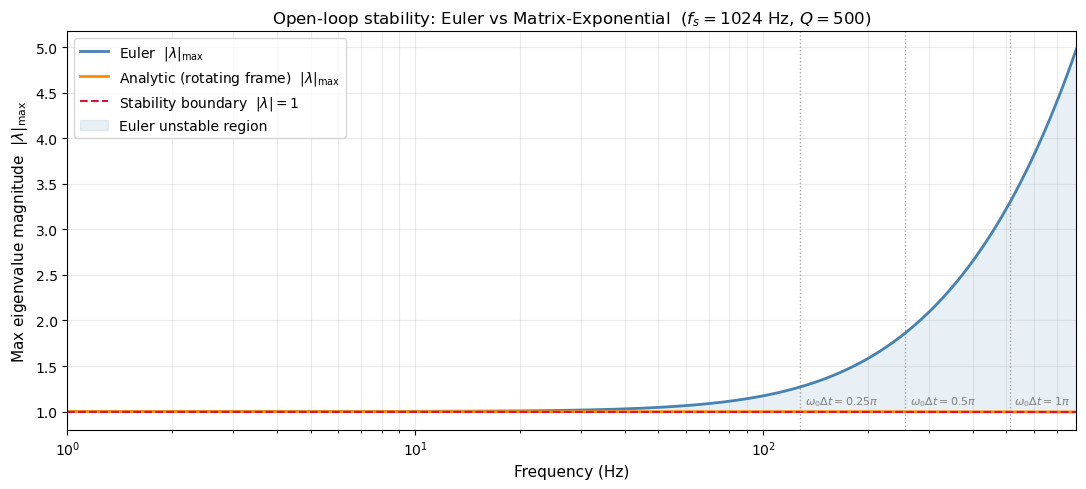

At f=100 Hz (ω₀Δt≈0.61 rad):
  Euler    |λ|_max = 1.171243  (>1 → diverges without gain)
  Analytic |λ|_max = 0.999389  (<1 → naturally decays)

Conclusion: use analytic=True for f0 > ~128 Hz at fs=1024 Hz


In [22]:

# -------------------------------------------------------------------
# Extension 1: Euler vs Matrix-Exponential — open-loop stability
# -------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

fs_demo = 1024          # Hz — representative audio/seismic sampling rate
dt_demo = 1.0 / fs_demo
freqs_sweep = np.logspace(0, 2.9, 300)   # 1 Hz … ~800 Hz

eig_euler    = []
eig_analytic = []

for f in freqs_sweep:
    w0 = 2.0 * np.pi * f
    Q_val = 500.0            # representative mechanical Q
    gamma = w0 / (2.0 * Q_val)

    # --- Euler F (OscillatorModel) ---
    # F = I + [[0,1],[-w0²,-b]]*dt  (b = w0/Q)
    b = w0 / Q_val
    F_e = np.array([[1.0,            dt_demo],
                    [-w0**2*dt_demo, 1.0 - b*dt_demo]])
    eig_euler.append(np.max(np.abs(np.linalg.eigvals(F_e))))

    # --- Analytic F (AnalyticOscillatorModel, rotating frame at wc=w0, dω=0) ---
    # In the rotating frame the continuous dynamics are [[-γ,0],[0,-γ]]; F=expm
    A_rot = np.array([[-gamma, 0.0],
                      [0.0,   -gamma]])
    F_a = expm(A_rot * dt_demo)
    eig_analytic.append(np.max(np.abs(np.linalg.eigvals(F_a))))

eig_euler    = np.array(eig_euler)
eig_analytic = np.array(eig_analytic)

# ω₀Δt reference lines
wdt_lines = [np.pi/4, np.pi/2, np.pi]
wdt_freqs = [v / (2*np.pi*dt_demo) for v in wdt_lines]

fig, ax = plt.subplots(figsize=(11, 5))
ax.semilogx(freqs_sweep, eig_euler,    lw=2.0, color='steelblue', label='Euler  $|\\lambda|_{\\max}$')
ax.semilogx(freqs_sweep, eig_analytic, lw=2.0, color='darkorange', label='Analytic (rotating frame)  $|\\lambda|_{\\max}$')
ax.axhline(1.0, color='crimson', ls='--', lw=1.5, label='Stability boundary  $|\\lambda|=1$')
ax.fill_between(freqs_sweep, 1.0, eig_euler,
                where=eig_euler > 1.0, alpha=0.12, color='steelblue',
                label='Euler unstable region')
for wdt, freq in zip(wdt_lines, wdt_freqs):
    ax.axvline(freq, color='gray', ls=':', lw=1.0, alpha=0.7)
    ax.text(freq*1.03, 1.0 + 0.01*(eig_euler.max()-1), f'$\\omega_0\\Delta t={wdt/np.pi:.2g}\\pi$',
            fontsize=8, color='gray', va='bottom')
ax.set_xlim(freqs_sweep[0], freqs_sweep[-1])
ax.set_xlabel('Frequency (Hz)', fontsize=11)
ax.set_ylabel('Max eigenvalue magnitude  $|\\lambda|_{\\max}$', fontsize=11)
ax.set_title(f'Open-loop stability: Euler vs Matrix-Exponential  ($f_s={fs_demo}$ Hz, $Q={Q_val:.0f}$)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.25, which='both')
plt.tight_layout()
plt.show()

print(f"At f=100 Hz (ω₀Δt≈{2*np.pi*100/fs_demo:.2f} rad):")
idx100 = np.argmin(np.abs(freqs_sweep - 100))
print(f"  Euler    |λ|_max = {eig_euler[idx100]:.6f}  (>1 → diverges without gain)")
print(f"  Analytic |λ|_max = {eig_analytic[idx100]:.6f}  (<1 → naturally decays)")
print(f"\nConclusion: use analytic=True for f0 > ~{wdt_freqs[0]:.0f} Hz at fs={fs_demo} Hz")



### Extension 3 — Innovation-Based Adaptive Process Noise (Sage-Husa)

A fixed $Q$ matrix sets the filter bandwidth: large $Q$ tracks fast changes but amplifies noise; small $Q$ is smooth but slow to respond.  
When the signal amplitude changes abruptly (impact, excitation switch), a fixed-$Q$ filter lags.

**Sage-Husa update** estimates $Q$ from a running window of innovations $\mathbf{y}_k = \mathbf{z}_k - H\hat{\mathbf{x}}_{k|k-1}$:
$$
\hat{Q}_k = (1 - d_k)\,\hat{Q}_{k-1} + d_k \bigl(K_k\,\mathbf{y}_k\mathbf{y}_k^\top K_k^\top\bigr)
$$
where $d_k = (1 - b)/(1 - b^{k+1})$ is a forgetting-factor weight ($b \in (0,1)$).

The demo generates a sinusoid whose amplitude **step-changes** mid-record and compares the fixed-$Q$ filter against the Sage-Husa adaptive filter.


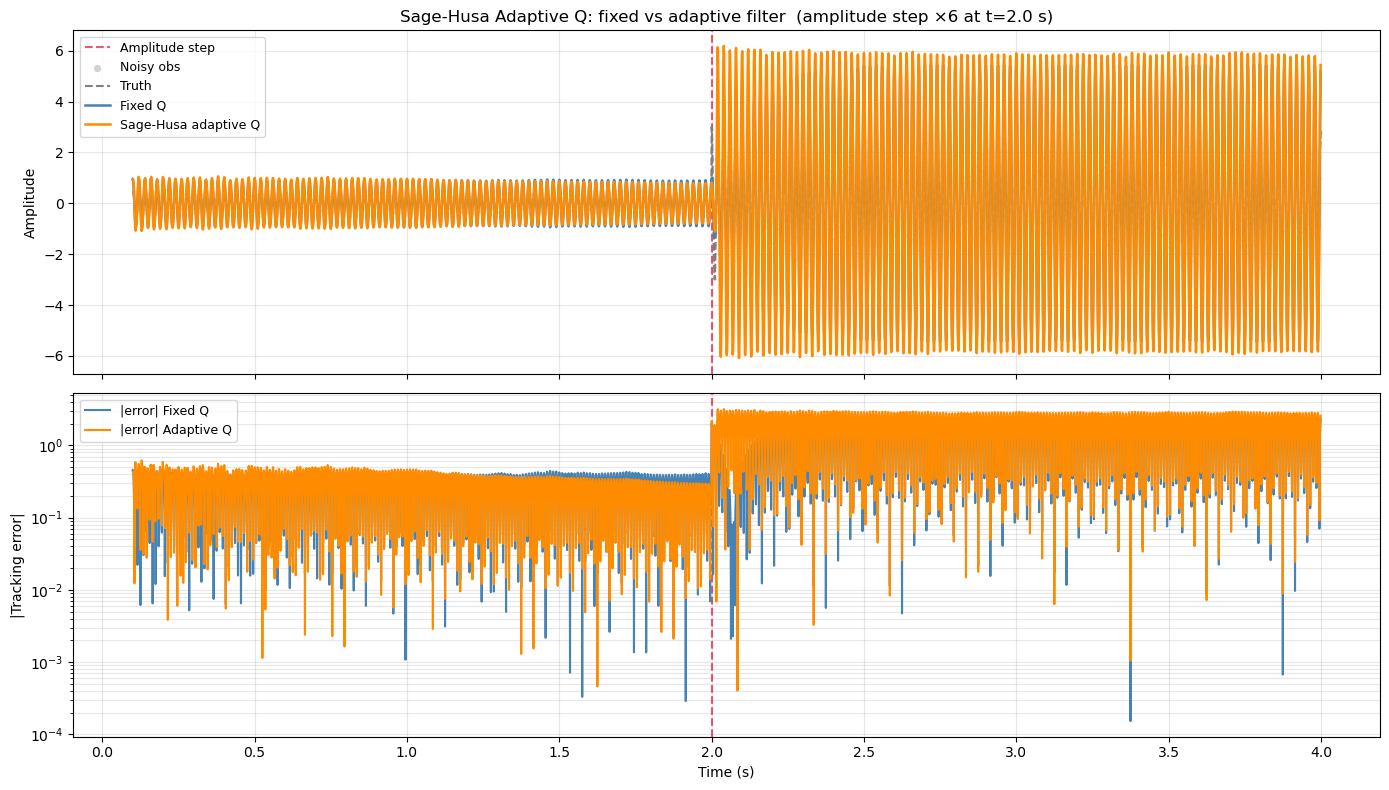

  Fixed Q: last sample >10% error at t=4.000 s  (recovery ≈ 2000 ms after step)
  Adaptive Q: last sample >10% error at t=4.000 s  (recovery ≈ 2000 ms after step)


In [23]:

# -------------------------------------------------------------------
# Extension 3: Sage-Husa adaptive process noise estimation
# -------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# ------------------------------------------------------------------
# Shared parameters
# ------------------------------------------------------------------
np.random.seed(42)

f0_sh    = 50.0      # Hz
Q_mech   = 200.0
fs_sh    = 1024.0
T_sh     = 4.0
N_sh     = int(T_sh * fs_sh)
t_sh     = np.arange(N_sh) / fs_sh
sigma_n  = 0.10
A_lo     = 0.5       # amplitude before step
A_hi     = 3.0       # amplitude after step
t_step   = T_sh / 2  # step at mid-record

# True signal: amplitude step at t_step
A_true_sh = np.where(t_sh < t_step, A_lo, A_hi)
signal_sh = A_true_sh * np.cos(2*np.pi*f0_sh*t_sh)
zk_sh     = signal_sh + sigma_n * np.random.randn(N_sh)

# ------------------------------------------------------------------
# Build the analytic (rotating-frame) state-space matrices
# ------------------------------------------------------------------
w0_sh    = 2.0 * np.pi * f0_sh
gamma_sh = w0_sh / (2.0 * Q_mech)
dt_sh    = 1.0 / fs_sh

F_sh = expm(np.array([[-gamma_sh, 0.0],
                       [0.0,      -gamma_sh]]) * dt_sh)
H_sh = np.eye(2)

Q0   = 1e-6  * np.eye(2)   # initial (small) process noise
R_sh = sigma_n**2 * np.sqrt(2) * np.eye(2)   # measurement noise (matches AnalyticOscillatorModel convention)

# ------------------------------------------------------------------
# Manual Kalman filter with optional Sage-Husa Q adaptation
# ------------------------------------------------------------------
def run_kf_analytic(zk_real, F, H, Q_init, R, w0, dt, adaptive=False,
                    forget=0.98, Q_floor=1e-8):
    """
    Run an analytic (rotating-frame) Kalman filter step-by-step.

    Parameters
    ----------
    adaptive : bool
        If True, update Q via Sage-Husa after each step.
    forget   : float
        Forgetting factor b ∈ (0,1); smaller → faster adaptation.
    Q_floor  : float
        Minimum diagonal value for Q (prevents degenerate covariance).
    """
    from scipy.signal import hilbert as scipy_hilbert

    N = len(zk_real)
    # Demodulate to rotating frame
    xa  = scipy_hilbert(zk_real)
    times = np.arange(N) * dt
    arg   = w0 * times
    zr    = xa.real * np.cos(arg) + xa.imag * np.sin(arg)
    zi    = xa.imag * np.cos(arg) - xa.real * np.sin(arg)
    zk_rot = np.column_stack([zr, zi])   # (N, 2) in rotating frame

    n = F.shape[0]
    x = np.zeros((n, 1))
    P = np.eye(n) * 1e3
    Q = Q_init.copy()

    xs = np.zeros((N, n))

    for k in range(N):
        # --- Predict ---
        xp = F @ x
        Pp = F @ P @ F.T + Q

        # --- Innovation ---
        z  = zk_rot[k].reshape(-1, 1)
        y  = z - H @ xp
        S  = H @ Pp @ H.T + R
        K  = Pp @ H.T @ np.linalg.solve(S, np.eye(S.shape[0]))

        # --- Update ---
        x = xp + K @ y
        P = (np.eye(n) - K @ H) @ Pp

        xs[k] = x.ravel()

        # --- Sage-Husa Q adaptation ---
        if adaptive:
            d_k = (1.0 - forget) / (1.0 - forget**(k + 1))
            Q_update = K @ (y @ y.T) @ K.T
            Q = (1.0 - d_k) * Q + d_k * Q_update
            # Enforce minimum Q and symmetry
            Q = 0.5 * (Q + Q.T)
            np.fill_diagonal(Q, np.maximum(np.diag(Q), Q_floor))

    return xs, zk_rot

xs_fixed, zk_rot = run_kf_analytic(zk_sh, F_sh, H_sh, Q0, R_sh, w0_sh, dt_sh,
                                    adaptive=False)
xs_adapt, _      = run_kf_analytic(zk_sh, F_sh, H_sh, Q0, R_sh, w0_sh, dt_sh,
                                    adaptive=True, forget=0.97)

# Reconstruct real signal from rotating-frame state
def reconstruct(xs, w0, t, dt):
    arg = w0 * t
    return 2*(xs[:, 0] * np.cos(arg) - xs[:, 1] * np.sin(arg))

recon_fixed = reconstruct(xs_fixed, w0_sh, t_sh, dt_sh)
recon_adapt = reconstruct(xs_adapt, w0_sh, t_sh, dt_sh)

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
skip_sh = int(0.1 * fs_sh)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].axvline(t_step, color='crimson', ls='--', lw=1.5, alpha=0.7, label='Amplitude step')
axes[0].scatter(t_sh[skip_sh:], zk_sh[skip_sh:], s=0.5, color='lightgray', label='Noisy obs', zorder=1)
axes[0].plot(t_sh[skip_sh:], signal_sh[skip_sh:],   '--', lw=1.5, color='gray',      label='Truth')
axes[0].plot(t_sh[skip_sh:], recon_fixed[skip_sh:],       lw=1.8, color='steelblue', label='Fixed Q')
axes[0].plot(t_sh[skip_sh:], recon_adapt[skip_sh:],       lw=1.8, color='darkorange', label='Sage-Husa adaptive Q')
axes[0].set_ylabel('Amplitude')
axes[0].set_title(f'Sage-Husa Adaptive Q: fixed vs adaptive filter  (amplitude step ×{A_hi/A_lo:.0f} at t={t_step:.1f} s)')
axes[0].legend(fontsize=9, markerscale=6)

# Error after step
err_fixed = np.abs(recon_fixed - signal_sh)
err_adapt = np.abs(recon_adapt - signal_sh)
axes[1].axvline(t_step, color='crimson', ls='--', lw=1.5, alpha=0.7)
axes[1].semilogy(t_sh[skip_sh:], err_fixed[skip_sh:], lw=1.5, color='steelblue', label='|error| Fixed Q')
axes[1].semilogy(t_sh[skip_sh:], err_adapt[skip_sh:], lw=1.5, color='darkorange', label='|error| Adaptive Q')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('|Tracking error|')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3, which='both')
axes[0].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Report recovery time: samples to get within 10% of new amplitude
step_idx = int(t_step * fs_sh)
for name, err in [("Fixed Q", err_fixed), ("Adaptive Q", err_adapt)]:
    thresh = 0.1 * A_hi
    above  = np.where(err[step_idx:] > thresh)[0]
    if len(above):
        rec_idx = above[-1] + 1 + step_idx
        print(f"  {name}: last sample >10% error at t={rec_idx/fs_sh:.3f} s  "
              f"(recovery ≈ {(rec_idx-step_idx)/fs_sh*1000:.0f} ms after step)")
    else:
        print(f"  {name}: always within 10% error")


## Extension 4 — InharmonicOscillatorModel: joint multi-mode subtraction

A single real strain channel contains **three inharmonic violin modes** (KAGRA-like,
sapphire suspension fibers). `InharmonicOscillatorModel` tracks all modes simultaneously
via independent Hilbert demodulation per partial (broadcast preprocess).

| Parameter | Value |
|---|---|
| Fundamental $f_0$ | 180.1 Hz |
| Inharmonicity $B$ | 0.105 (KAGRA sapphire) |
| Mode 1 / 2 / 3 $Q$ | 1.3×10⁴ / 1.8×10⁴ / 2.1×10⁴ |
| Mode amplitudes | 1×10⁻¹⁸ / 3×10⁻¹⁹ / 1.5×10⁻¹⁹ m/√Hz |
| Noise floor | 5×10⁻¹⁹ m/√Hz |

Violin mode frequencies: [189.32 429.23 753.52] Hz
Inharmonicity B = 0.105  (mode-2 shift: +69.0 Hz from harmonic grid)

Mode suppression:
  Mode 1 (189.3 Hz): +53.7 dB
  Mode 2 (429.2 Hz): +42.8 dB
  Mode 3 (753.5 Hz): +32.6 dB


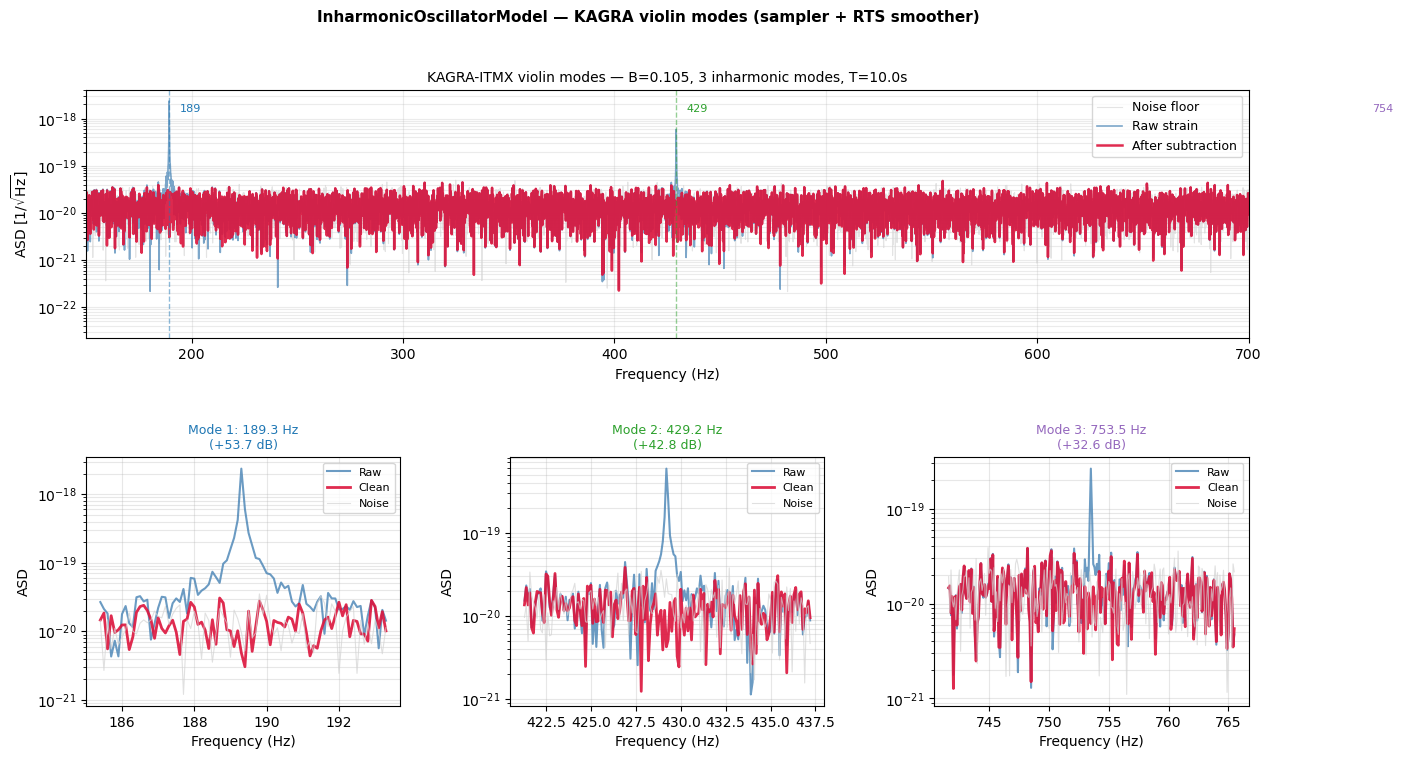

In [24]:
# -------------------------------------------------------------------
# Extension 4: InharmonicOscillatorModel — joint multi-mode subtraction
# -------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from kalman.apps.oscillators import InharmonicOscillatorModel
from numpy.fft import rfft, rfftfreq

# ------------------------------------------------------------------
# KAGRA-like violin mode parameters
# (inspired by Moisset et al. 2025, Table II — fiber set #1 mean values)
# ------------------------------------------------------------------
f0_vf, B_vf, n_modes = 180.1, 0.105, 3
fs_vf, T_vf = 4096.0, 10.0
N_vf = int(T_vf * fs_vf)
noise_std = 5e-19
Q_list = [1.3e4, 1.8e4, 2.1e4]
A_list = [1.0e-18, 3.0e-19, 1.5e-19]

partial_freqs_vf = InharmonicOscillatorModel.partial_frequencies(f0_vf, B_vf, n_modes)
print(f"Violin mode frequencies: {np.round(partial_freqs_vf, 2)} Hz")
print(f"Inharmonicity B = {B_vf:.3f}  "
      f"(mode-2 shift: +{partial_freqs_vf[1]-2*f0_vf:.1f} Hz from harmonic grid)")

# ------------------------------------------------------------------
# Build model first — sampler uses model.x0 and internal dynamics
# ------------------------------------------------------------------
model_vf = InharmonicOscillatorModel(
    'KAGRA-ITMX',
    f0=f0_vf, n_harmonics=n_modes, B=B_vf, fs=fs_vf,
    Q_factor=Q_list,
    measurement_uncertainty=noise_std,
    process_uncertainty=1e-26,
)
for m, A in zip(model_vf.models, A_list):
    m.initial_state([A, 0.0])
model_vf.initial_state(np.vstack([m.x0 for m in model_vf.models]))

# ------------------------------------------------------------------
# Signal generation via sampler
# sample(T, measurement_noise=False) propagates the state trajectory
# using the model's internal dynamics (process noise + Q decay).
# reconstruct() converts the rotating-frame xk back to the lab-frame signal.
# ------------------------------------------------------------------
np.random.seed(0)
sample_vf = model_vf.sample(T_vf, measurement_noise=False)

t_vf = np.arange(N_vf) / fs_vf
modes_true = [
    sample_vf.xk[:, 2*i] * np.cos(sub["wc"] * t_vf)
    - sample_vf.xk[:, 2*i+1] * np.sin(sub["wc"] * t_vf)
    for i, sub in enumerate(model_vf.models)
]
strain_vf = sum(modes_true) + noise_std * np.random.randn(N_vf)

# ------------------------------------------------------------------
# Filter  (same model, reset=True restores x0)
# ------------------------------------------------------------------
record_vf = model_vf.filter(strain_vf.reshape(-1, 1), smooth=True, reset=True)
modes_hat, strain_clean_vf = model_vf.extract(record_vf, strain_vf)

# ------------------------------------------------------------------
# ASD
# ------------------------------------------------------------------
freqs_vf_f = rfftfreq(N_vf, 1.0 / fs_vf)
norm_vf    = 2.0 / np.sqrt(fs_vf * N_vf)
S_raw   = np.abs(rfft(strain_vf))        * norm_vf
S_clean = np.abs(rfft(strain_clean_vf))  * norm_vf
S_noise = np.abs(rfft(noise_std * np.random.randn(N_vf))) * norm_vf

# Per-mode suppression
print("\nMode suppression:")
for k, (fn, mode_true, mode_hat) in enumerate(zip(partial_freqs_vf, modes_true, modes_hat)):
    idx = np.argmin(np.abs(freqs_vf_f - fn))
    db  = 20 * np.log10(S_raw[idx] / S_clean[idx]) if S_clean[idx] > 0 else float('inf')
    print(f"  Mode {k+1} ({fn:.1f} Hz): {db:+.1f} dB")

# ------------------------------------------------------------------
# Figure: 2×3 grid — full ASD + per-mode zooms
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 8))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.35)

ax0 = fig.add_subplot(gs[0, :])
ax0.semilogy(freqs_vf_f, S_noise, color='lightgray', lw=0.8, alpha=0.6, label='Noise floor')
ax0.semilogy(freqs_vf_f, S_raw,   color='steelblue', lw=1.2, alpha=0.7, label='Raw strain')
ax0.semilogy(freqs_vf_f, S_clean, color='crimson',   lw=1.8, alpha=0.9, label='After subtraction')
colors_m = ['tab:blue', 'tab:green', 'tab:purple']
for fn, col in zip(partial_freqs_vf, colors_m):
    ax0.axvline(fn, ls='--', color=col, lw=1.0, alpha=0.5)
    ax0.text(fn + 5, S_raw.max() * 0.6, f'{fn:.0f}', fontsize=8, color=col)
ax0.set_xlim(150, 700)
ax0.set_xlabel('Frequency (Hz)'); ax0.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax0.set_title(f'KAGRA-ITMX violin modes — B={B_vf}, {n_modes} inharmonic modes, T={T_vf}s', fontsize=10)
ax0.legend(fontsize=9); ax0.grid(True, alpha=0.25, which='both')

for col_idx, (fn, col) in enumerate(zip(partial_freqs_vf, colors_m)):
    ax = fig.add_subplot(gs[1, col_idx])
    bw  = 4.0 * (col_idx + 1)
    msk = (freqs_vf_f > fn - bw) & (freqs_vf_f < fn + bw)
    ax.semilogy(freqs_vf_f[msk], S_raw[msk],   color='steelblue', lw=1.5, alpha=0.8, label='Raw')
    ax.semilogy(freqs_vf_f[msk], S_clean[msk], color='crimson',   lw=2.0, alpha=0.9, label='Clean')
    ax.semilogy(freqs_vf_f[msk], S_noise[msk], color='lightgray', lw=0.8, alpha=0.7, label='Noise')
    idx = np.argmin(np.abs(freqs_vf_f - fn))
    db  = 20 * np.log10(S_raw[idx] / S_clean[idx]) if S_clean[idx] > 0 else float('inf')
    ax.set_title(f'Mode {col_idx+1}: {fn:.1f} Hz\n({db:+.1f} dB)', fontsize=9, color=col)
    ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('ASD')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3, which='both')

fig.suptitle(f'InharmonicOscillatorModel — KAGRA violin modes (sampler + RTS smoother)',
             fontsize=11, fontweight='bold')
plt.show()
